##### Step 6: Feature engineering and train/test split  
6A. Create a new notebook: notebooks/05_modeling.ipynb

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/model_table.csv", parse_dates=["order_purchase_timestamp"])
df = df[df["order_purchase_timestamp"] >= "2017-01-01"].copy()
print(df.shape, df["is_late"].mean().round(3))

(96203, 31) 0.081


6B. New features (all known at purchase time)

In [2]:
df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)
df["is_weekend"]    = (df["purchase_weekday"] >= 5).astype(int)
df["price_per_item"] = df["total_price"] / df["n_items"]

Feature	                    Why  
__freight_ratio__	Expensive shipping relative to price often means a heavy or remote order  
__is_weekend__	Weekend orders wait for processing  
__price_per_item__	Separates bulk orders from single items

__If skipped:__ The model sees only raw columns and misses these ratios, which trees can’t easily build on their own.

6C. Remove leaky and useless columns

In [3]:
drop_cols = ["delivery_days",               # known only after delivery = LEAKAGE
             "order_id", "customer_id", 
             "customer_unique_id", 
             "seller_id",                   # IDs memorize, not generalize
             "customer_zip_code_prefix", 
             "seller_zip_code_prefix",     # too many unique values
             "cust_lat", "cust_lng", 
             "sell_lat", "sell_lng",       # distance_km already captures them
             "payment_value"]              # near-duplicate of total_price + freight
y = df["is_late"]
X = df.drop(columns=drop_cols + ["is_late"])
print(X.columns.tolist())

['order_purchase_timestamp', 'estimated_days', 'customer_state', 'n_items', 'n_sellers', 'total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'category', 'max_installments', 'payment_type', 'seller_state', 'distance_km', 'same_state', 'purchase_month', 'purchase_weekday', 'purchase_hour', 'freight_ratio', 'is_weekend', 'price_per_item']


Why drop IDs: The model would memorize individual rows and fail on new data.
If delivery_days stays: You get about 99% accuracy in testing, and the model is useless in real life.

6D. Time-based split

In [4]:
df_sorted = df.sort_values("order_purchase_timestamp")
cut =  int(len(df_sorted) * 0.8)
train, test = df_sorted.iloc[:cut], df_sorted.iloc[cut:]

X_train = train.drop(columns=drop_cols + ["is_late"]); y_train = train["is_late"]
X_test  = test.drop(columns=drop_cols + ["is_late"]);  y_test  = test["is_late"]

print(len(X_train), len(X_test))
print("Late rate train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))
print("Test period:", test["order_purchase_timestamp"].min().date(), "to", test["order_purchase_timestamp"].max().date())

76962 19241
Late rate train: 0.088 | test: 0.053
Test period: 2018-05-27 to 2018-08-29


Why time-based, not random: In real life you predict future orders from past ones. A random split lets the model peek at the future and gives over-optimistic scores.  
Why 80/20: It leaves enough data to learn from while keeping a test set large enough to be reliable.  
__Rule:__ Never touch the test set until the final evaluation. Tuning on it is cheating.

6E. Save and commit

In [5]:
X_train.assign(is_late=y_train).to_csv("../data/processed/train.csv", index=False)
X_test.assign(is_late=y_test).to_csv("../data/processed/test.csv", index=False)

`powershell`  
git add .  
git commit -m "Step 6: feature engineering and time-based split"  
git push  

In [6]:
print(y_train.mean().round(3), y_test.mean().round(3))

0.088 0.053


First: your late rates reveal drift

Train 8.8% vs test 5.3%. This is a real shift, not a bug. Orders from late 2017 to early 2018 (Black Friday and other peaks) were delayed more often than orders from May to Aug 2018. Check it:

In [7]:
print(df.groupby(df["order_purchase_timestamp"].dt.to_period("M"))["is_late"].mean().round(3))

order_purchase_timestamp
2017-01    0.031
2017-02    0.032
2017-03    0.056
2017-04    0.079
2017-05    0.036
2017-06    0.039
2017-07    0.034
2017-08    0.033
2017-09    0.052
2017-10    0.053
2017-11    0.143
2017-12    0.084
2018-01    0.066
2018-02    0.160
2018-03    0.214
2018-04    0.053
2018-05    0.082
2018-06    0.014
2018-07    0.045
2018-08    0.104
Freq: M, Name: is_late, dtype: float64


What it means for you:

The test baseline is 5.3%, so a random model gets a PR-AUC of about 0.053, not 0.088. Always compare against the test rate.
Precision will look lower on test, because there are fewer late orders to find.  
Mention this drift in your report. It is an honest, real-world limitation.

Step 7: Preprocessing pipeline and baseline models

Why a pipeline: It learns imputation values and scaling from train only, then applies the same rules to test.
If skipped: Filling or scaling with the full data lets test information leak into training, and your scores look better than reality.

7A. Load and separate columns

In [8]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score, confusion_matrix

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

y_train, y_test = train.pop("is_late"), test.pop("is_late")
X_train = train.drop(columns=["order_purchase_timestamp"])  # raw timestamp can't go in the model; month/hour/weekday already capture it
X_test = test.drop(columns = ["order_purchase_timestamp"])

cat_cols = ["customer_state", "seller_state", "category", "payment_type"]
num_cols = [c for c in X_train.columns if c not in cat_cols]
print(len(num_cols), num_cols)   # expect 16

16 ['estimated_days', 'n_items', 'n_sellers', 'total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'max_installments', 'distance_km', 'same_state', 'purchase_month', 'purchase_weekday', 'purchase_hour', 'freight_ratio', 'is_weekend', 'price_per_item']


7B. Build the preprocessor

In [9]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh",  OneHotEncoder(handle_unknown="ignore", min_frequency=100))]), cat_cols),
])

| Part |	Why | If skipped |  
|----------| ---------------------------- | -------------------------- |  
Median imputer	| Fills the nulls we kept (distance, weight, payment). The median resists outliers.	| The model crashes on NaN  |    
| StandardScaler |	Puts price (R$ 1000s) and same_state (0/1) on one scale. Needed for logistic regression. |	Large-valued columns dominate  |  
| OneHotEncoder |	Turns state/category text into 0/1 columns |	The model can’t read text  |  
| handle_unknown="ignore" |	A new category in test won’t crash |	Crash on unseen values |    
| min_frequency=100 | 	Rare categories group into one “other” column |	Hundreds of noisy columns |    

7C. Evaluate two baselines

In [10]:
def evaluate(name, clf):
    model = Pipeline([("prep", preprocess), ("clf", clf)])
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred, digits=3))
    print("PR-AUC :", round(average_precision_score(y_test, proba), 3),
          "| ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
    print(confusion_matrix(y_test, pred))
    return model

dummy = evaluate("Dummy: always on-time", DummyClassifier(strategy="most_frequent"))
logit = evaluate("Logistic Regression", LogisticRegression(max_iter=1000, class_weight="balanced"))


===== Dummy: always on-time =====
              precision    recall  f1-score   support

           0      0.947     1.000     0.973     18221
           1      0.000     0.000     0.000      1020

    accuracy                          0.947     19241
   macro avg      0.473     0.500     0.486     19241
weighted avg      0.897     0.947     0.921     19241

PR-AUC : 0.053 | ROC-AUC: 0.5
[[18221     0]
 [ 1020     0]]


d:\projects_on_DataAnalyst\olist-delivery-prediction\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\projects_on_DataAnalyst\olist-delivery-prediction\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\projects_on_DataAnalyst\olist-delivery-prediction\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war


===== Logistic Regression =====
              precision    recall  f1-score   support

           0      0.981     0.548     0.703     18221
           1      0.091     0.811     0.164      1020

    accuracy                          0.561     19241
   macro avg      0.536     0.679     0.433     19241
weighted avg      0.934     0.561     0.674     19241

PR-AUC : 0.116 | ROC-AUC: 0.722
[[9976 8245]
 [ 193  827]]


Why these two

`Dummy`: Predicts “on-time” for everything. Expect about 94.7% accuracy and 0% recall. This proves accuracy is a trap, and it is the floor every real model must beat.  
`Logistic Regression`: A simple, fast, explainable baseline. If XGBoost can’t beat it clearly, the extra complexity isn’t worth it.  
`class_weight="balanced"`: Without it, the model sees 92% on-time and learns to say “on-time” every time. This makes the rare late class count more in training.

7D. Commit

git add .  
git commit -m "Step 7: preprocessing pipeline and baseline models"  
git push

Step 8: Random Forest and XGBoost

Why these models: Our data is tabular, with mixed types and nonlinear patterns (distance matters more past a certain point, and state interacts with category). Tree models capture this automatically. If they don’t beat Logistic Regression clearly, the extra complexity isn’t worth it.

8A. Better comparison function

In [11]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def evaluate(name, clf):
    model = Pipeline([("prep", preprocess), ("clf", clf)])
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    yt = y_test.values
    top = proba >= np.quantile(proba, 0.9)          # the riskiest 10% of orders
    return model, {"model": name,
                   "PR-AUC": round(average_precision_score(yt, proba), 3),
                   "ROC-AUC": round(roc_auc_score(yt, proba), 3),
                   "precision@top10%": round(yt[top].mean(), 3),
                   "recall@top10%": round(yt[top].sum() / yt.sum(), 3)}

Why “top 10%”: An operations team can only check or expedite a limited number of orders. This metric answers: “if we review the 10% riskiest orders, how many late ones do we catch?” It is also threshold-free.


8B. Train and compare

In [12]:
spw = (y_train == 0).sum() / (y_train == 1).sum()   # about 10: weight of late class

models = {
    "Logistic": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=50,
                                           class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=spw, n_jobs=-1, random_state=42),
}

fitted, rows = {}, []
for name, clf in models.items():
    fitted[name], r = evaluate(name, clf)
    rows.append(r)

results = pd.DataFrame(rows).set_index("model")
print(results)
print("Random baseline: PR-AUC 0.053, precision@top10% 0.053")

              PR-AUC  ROC-AUC  precision@top10%  recall@top10%
model                                                         
Logistic       0.116    0.722             0.112          0.212
RandomForest   0.062    0.531             0.076          0.143
XGBoost        0.107    0.713             0.116          0.219
Random baseline: PR-AUC 0.053, precision@top10% 0.053


| Setting |	Why	| If skipped |  
|---------|--------| ---------|  
|max_depth, min_samples_leaf|	Limit tree size, which prevents memorizing train data|	Overfit: great train score, poor test score |
|scale_pos_weight	|Makes the rare late class count about 10x more	| The model ignores late orders|
|random_state=42	|Same result every run	|Results change each run, and the report can’t be reproduced|
|Same preprocess for all|	A fair comparison|	You can’t tell which model won|

Why not other algorithms: KNN is slow on 77k rows and needs scaling. SVM is slow at this size and gives no easy probabilities. Neural networks need more data and are hard to explain on this tabular data.

8C. Save the table and commit

In [13]:
results.to_csv("../reports/model_comparison.csv")

git add .  
git commit -m "Step 8: RF and XGBoost comparison"  
git push

Step 9: Diagnose before tuning

Tuning a model that fails because of drift wastes time. First we find the cause.

9A. Answer the pending items

In [14]:
# Monthly late rate
full = pd.read_csv("../data/processed/model_table.csv", parse_dates=["order_purchase_timestamp"])
print(full.groupby(full["order_purchase_timestamp"].dt.to_period("M"))["is_late"].mean().round(3))

# Dummy baseline
dummy = Pipeline([("prep", preprocess), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
p = dummy.predict(X_test)
print("accuracy:", round((p == y_test).mean(), 3), "| late recall:", round(p[y_test == 1].mean(), 3))

order_purchase_timestamp
2016-09    1.000
2016-10    0.011
2016-12    0.000
2017-01    0.031
2017-02    0.032
2017-03    0.056
2017-04    0.079
2017-05    0.036
2017-06    0.039
2017-07    0.034
2017-08    0.033
2017-09    0.052
2017-10    0.053
2017-11    0.143
2017-12    0.084
2018-01    0.066
2018-02    0.160
2018-03    0.214
2018-04    0.053
2018-05    0.082
2018-06    0.014
2018-07    0.045
2018-08    0.104
Freq: M, Name: is_late, dtype: float64
accuracy: 0.947 | late recall: 0.0


Expected: accuracy about 0.947 and recall 0.000. This shows 94.7% accuracy with zero usefulness, which is why we don’t use accuracy.

9B. Experiment: drop time-specific features

In [15]:
def make_prep(nums):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), nums),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=100))]), cat_cols)])

def run(name, clf, drop):
    nums = [c for c in num_cols if c not in drop]
    m = Pipeline([("prep", make_prep(nums)), ("clf", clf)]).fit(X_train.drop(columns=drop), y_train)
    proba = m.predict_proba(X_test.drop(columns=drop))[:, 1]
    top = proba >= np.quantile(proba, 0.9); yt = y_test.values
    return {"model": name, "dropped": drop or "none",
            "PR-AUC": round(average_precision_score(yt, proba), 3),
            "ROC-AUC": round(roc_auc_score(yt, proba), 3),
            "recall@top10%": round(yt[top].sum() / yt.sum(), 3)}

rows = []
for drop in [[], ["purchase_month"]]:
    rows.append(run("RandomForest", models["RandomForest"], drop))
    rows.append(run("XGBoost", models["XGBoost"], drop))
print(pd.DataFrame(rows))

          model           dropped  PR-AUC  ROC-AUC  recall@top10%
0  RandomForest              none   0.062    0.531          0.143
1       XGBoost              none   0.107    0.713          0.219
2  RandomForest  [purchase_month]   0.057    0.491          0.135
3       XGBoost  [purchase_month]   0.083    0.621          0.166


`What to look for`: If Random Forest’s ROC-AUC jumps from 0.53 to about 0.7 after dropping purchase_month, the hypothesis is confirmed. Calendar features hurt generalization, and you must explain that in your report.  
If nothing changes: The cause is something else, and we check feature importance next.

9C. Commit

git add .  
git commit -m "Step 9: drift diagnosis, month ablation"  
git push

Step 10: Final model, decision rule, business evaluation

Your Step 9 results (monthly late rates, Dummy, ablation table) are still pending. This step doesn’t depend on them, so we go ahead with Logistic Regression, which had the best PR-AUC. If the ablation shows a tree model clearly beating it, change one line (final = ...) and re-run.

Why this step exists

A model outputs probabilities, and the business needs a decision: which orders to flag? Choosing the rule badly wastes money, either by flagging everything or by missing most late orders.

Do not tune the rule on the test set. That is cheating, and your score becomes fake.

10A. Use a capacity-based rule, not a fixed 0.5 cutoff

An operations team can review a fixed share of orders (for example 10%), so we flag the top k% riskiest orders.

Why not “probability ≥ 0.5”: Our late rate drifted from 8.8% to 5.3%. A fixed probability cutoff shifts with drift, but “top 10%” always flags the same workload.


In [16]:
final = fitted["Logistic"]          # swap here if another model wins
proba = final.predict_proba(X_test)[:, 1]
yt = y_test.values

rows = []
for k in [0.05, 0.10, 0.20, 0.30]:
    flag = proba >= np.quantile(proba, 1 - k)
    tp = yt[flag].sum()
    rows.append({"review_top_%": int(k * 100),
                 "orders_flagged": int(flag.sum()),
                 "late_caught": int(tp),
                 "precision": round(tp / flag.sum(), 3),
                 "recall": round(tp / yt.sum(), 3),
                 "lift_vs_random": round((tp / flag.sum()) / yt.mean(), 2)})
table = pd.DataFrame(rows)
print(table)
print("Total late orders in test:", int(yt.sum()))

   review_top_%  orders_flagged  late_caught  precision  recall  \
0             5             963          139      0.144   0.136   
1            10            1925          216      0.112   0.212   
2            20            3849          384      0.100   0.376   
3            30            5773          605      0.105   0.593   

   lift_vs_random  
0            2.72  
1            2.12  
2            1.88  
3            1.98  
Total late orders in test: 1020


|Column|	Meaning|
|----------|--------|
|precision|	Of the flagged orders, the share really late|
|recall	|Of all late orders, the share we caught|
|lift|	How many times better than picking randomly (1.0 = random)|

10B. Confusion matrix at the chosen workload (top 10%)

                pred ok  pred flagged
actual on-time    16512          1709
actual late         804           216


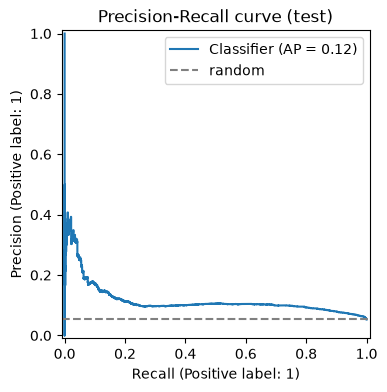

In [17]:
from sklearn.metrics import confusion_matrix, PrecisionRecallDisplay
import matplotlib.pyplot as plt

flag = (proba >= np.quantile(proba, 0.90)).astype(int)
cm = confusion_matrix(yt, flag)
print(pd.DataFrame(cm, index=["actual on-time", "actual late"], columns=["pred ok", "pred flagged"]))

fig, ax = plt.subplots(figsize=(6, 4))
PrecisionRecallDisplay.from_predictions(yt, proba, ax=ax)
ax.axhline(yt.mean(), ls="--", c="gray", label="random")
ax.legend(); ax.set_title("Precision-Recall curve (test)")
plt.savefig("../reports/figures/04_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

table.to_csv("../reports/final_results.csv", index=False)

10C. How to choose k (business logic, not math)  

|If expediting an order costs...| 	Choose |
|---------|-------|
|Little (a message or priority label)|	Larger k (20 to 30%), higher recall|
|A lot (reshipping, calling the carrier)|	Smaller k (5 to 10%), higher precision|

Each late order drops the average review from about 4.3 to 2.6, which is the cost of missing one. State your chosen k in the report with this reasoning.

10D. Commit

git add .  
git commit -m "Step 10: final model, capacity-based   decision rule"
git push

Step 11: Explainability (SHAP)

Why: A manager won’t trust “the model says risky”. SHAP shows which features push an order toward late.
If skipped: You can’t explain the model, and interviewers always ask “what drives late delivery?”

Background dataset has 76962 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=76962 when initializing the masker.


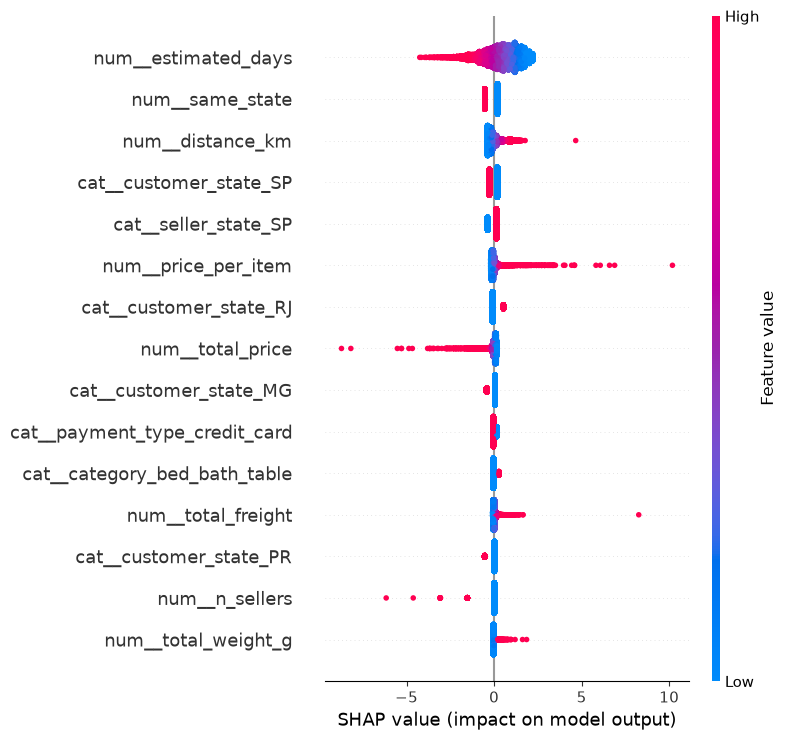

In [18]:
import shap, matplotlib.pyplot as plt

prep = final.named_steps["prep"]; clf = final.named_steps["clf"]
dense = lambda a: a.toarray() if hasattr(a, "toarray") else a
Xtr, Xte = dense(prep.transform(X_train)), dense(prep.transform(X_test))
names = prep.get_feature_names_out()

sv = shap.LinearExplainer(clf, Xtr)(Xte)
shap.summary_plot(sv.values, Xte, feature_names=names, max_display=15, show=False)
plt.savefig("../reports/figures/05_shap.png", dpi=150, bbox_inches="tight")
plt.show()

How to read the plot: Each dot is one order. Features at the top matter most. Dots to the right push toward late, and red means a high feature value. If a model other than Logistic wins the ablation, I’ll swap in TreeExplainer.  

powershell  
git add .  
git commit -m "Step 11: SHAP explainability"  
git push

In [19]:
print(X_train[["estimated_days", "distance_km", "total_price", "price_per_item"]].corr().round(2))

                estimated_days  distance_km  total_price  price_per_item
estimated_days            1.00         0.55         0.07            0.07
distance_km               0.55         1.00         0.08            0.08
total_price               0.07         0.08         1.00            0.93
price_per_item            0.07         0.08         0.93            1.00


##### Step 12: Save the model and a prediction function

Why: A model that only lives in a notebook can’t be reused. Saving it lets anyone score new orders.
If skipped: The project is a one-off analysis, not a usable system.

12A. Save

In [20]:
import joblib, json
joblib.dump(final, "../models/late_delivery_logreg.joblib")
json.dump({"columns": X_train.columns.tolist()}, open("../models/meta.json", "w"))

12B. Create src/predict.py and an empty src/__ __init__ __.py

Why flag by batch share, not a fixed probability: Our late rate drifted between periods, so a fixed cutoff would flag too many or too few orders. The top-k% rule keeps the workload stable.

12C. Test it

In [22]:
import sys; sys.path.append("..")
from src.predict import predict_risk, flag_top
print(predict_risk(X_test.head()))
print(flag_top(X_test).mean())      # should be about 0.10

0    0.055933
1    0.251294
2    0.139267
3    0.156754
4    0.073105
Name: late_risk, dtype: float64
0.10004677511563848


Commit:  
pip freeze > requirements.txt  
git add .  
git commit -m "Step 12: save model and predict function"  
git push

`requirements.txt` matters because a joblib file only loads reliably with the same scikit-learn version.

__Q__:For SHAP: does a high estimated_days push orders toward late (right side) or away (left side)? Check the color and position on your plot.  
Answering the SHAP question with a number

Reading colors on a plot is hard, so get it from the model directly:

In [23]:
names = list(final.named_steps["prep"].get_feature_names_out())
coef = pd.Series(final.named_steps["clf"].coef_[0], index=names).sort_values()
print(coef.head(5).round(2))    # push toward on-time
print(coef.tail(5).round(2))    # push toward late

cat__customer_state_RO       -1.09
cat__seller_state_PE         -0.94
num__estimated_days          -0.72
cat__category_computers      -0.69
cat__category_market_place   -0.62
dtype: float64
cat__category_christmas_supplies    0.55
cat__category_audio                 0.55
cat__customer_state_RJ              0.61
cat__customer_state_AL              1.01
cat__seller_state_MA                1.45
dtype: float64


How to read it: A positive coefficient means a higher value raises late risk. A negative one lowers it. Numeric features are standardized, so their sizes are comparable. Send me the top 5 positive coefficients and I’ll help you write the interpretation.

You also still owe me the correlation table:

In [24]:
print(X_train[["estimated_days", "distance_km", "total_price", "price_per_item"]].corr().round(2))

                estimated_days  distance_km  total_price  price_per_item
estimated_days            1.00         0.55         0.07            0.07
distance_km               0.55         1.00         0.08            0.08
total_price               0.07         0.08         1.00            0.93
price_per_item            0.07         0.08         0.93            1.00


Step 13: Report and README

Why: Recruiters spend about 2 minutes on a repo. They read the README, not your notebooks.
If skipped: Strong work looks like nothing.

13A. README.md (fill the <...> after you get the coefficient output)

# Olist Late-Delivery Prediction

Predict at purchase time whether a Brazilian e-commerce order will arrive after its estimated date, so the business can warn customers early.

## Data
Olist Brazilian E-Commerce (Kaggle): 9 real tables, about 100k orders, 2016-2018.
Chosen because it is real, multi-table (joins), imbalanced, and covers numeric, date, text and geographic data.

## Key findings
- 8.1% of orders arrive late; Olist pads its estimates by about 11 days (estimated 23.4 days vs actual 12.1).
- Late delivery cuts the average review from 4.29 to 2.57.
- Late rate rises with distance: 6.5% (closest fifth) to 11% (farthest fifth).
- Northeast states are worst (AL about 24%, MA about 20%); PR, MG and SP are about 5-6%.
- Revenue peaked in Nov 2017 (Black Friday).

## Model
Time-based split (train Jan 2017 to May 2018, test May to Aug 2018), no leakage.
| Model | PR-AUC | ROC-AUC |
|---|---|---|
| Random baseline | 0.053 | 0.500 |
| Logistic Regression (final) | 0.116 | 0.722 |
| XGBoost | 0.107 | 0.713 |
| Random Forest | 0.062 | 0.531 |

Reviewing the riskiest 10% of orders catches 21% of late orders at 11.2% precision (2.1x random).

## Limitations
- Weak signal: seller speed and carrier delays are unknown at purchase time.
- Late rate drifted (8.8% train vs 5.3% test).
- Scores are for ranking, not calibrated probabilities.

## Run it
pip install -r requirements.txt, then run notebooks in order.

## Stack
Python, pandas, scikit-learn, XGBoost, SHAP, Git

13B. reports/report.md outline (one short paragraph per section)

1. Problem and business value: why late delivery matters (the review drop)
2. Data and why chosen
3. Cleaning decisions: delivered orders only, zero weight treated as missing, outliers kept
4. EDA insights: the 5 findings above, with 2 or 3 figures from reports/figures/
5. Method: time-based split, leakage rules, pipeline fitted on train only
6. Models and why: baseline first, then trees, and why Logistic won
7. Results: the table, the confusion matrix, and the 10% triage numbers
8. Drift test: hypothesis (purchase_month caused the Random Forest failure), result (rejected, because dropping it made models worse), which shows honest analysis
9. Drivers: the top coefficients or SHAP in plain words
10. Limitations and next steps: add seller history features, retrain monthly, test calibration

13C. Commit

powershell  
git add .  
git commit -m "Step 13: README and report"  
git push

Check before you write conclusions

Small states can produce extreme coefficients from few orders. Verify the counts:

In [25]:
for col, val in [("customer_state","RO"), ("customer_state","AL"), ("seller_state","MA"), ("seller_state","PE")]:
    print(col, val, (X_train[col] == val).sum())

customer_state RO 206
customer_state AL 331
seller_state MA 163
seller_state PE 297
